# 🔢 Nhận Diện Chữ Số Viết Tay MNIST Bằng Mạng Nơ-ron Tích Chập (CNN)

**Mục tiêu**: Xây dựng, huấn luyện và lưu trữ một mô hình **Convolutional Neural Network (CNN)** có độ sâu trên 5 layer để phân loại chữ số viết tay từ tập dữ liệu MNIST.  
**Dữ liệu sử dụng**:
- `data/mnist_train.csv`: 60,000 mẫu huấn luyện.
- `data/mnist_test.csv`: 10,000 mẫu kiểm thử.

---

### 📌 Bước 1: Khai báo các thư viện cần thiết
Sử dụng **TensorFlow/Keras** để xây dựng mô hình Deep Learning, **NumPy/Pandas** để xử lý dữ liệu và **Matplotlib/Seaborn** để vẽ đồ thị đánh giá.

In [1]:
import os
import time
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Tắt bớt log cảnh báo từ TensorFlow
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Cố định seed ngẫu nhiên để kết quả có thể tái lập
np.random.seed(42)
tf.random.set_seed(42)

print(f"✅ TensorFlow Version: {tf.__version__}")
print(f"✅ Keras Version     : {keras.__version__}")
print(f"✅ Thiết bị khả dụng : {tf.config.list_physical_devices()}")

✅ TensorFlow Version: 2.22.0-rc0
✅ Keras Version     : 3.15.1
✅ Thiết bị khả dụng : [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


### 📌 Bước 2: Tải dữ liệu từ mnist_train.csv và mnist_test.csv
Đọc dữ liệu bảng. Cột `label` chứa nhãn chữ số (0 - 9), 784 cột còn lại tương ứng với 784 điểm ảnh (28x28 pixel) với dải giá trị từ 0 đến 255.

In [2]:
train_path = 'data/mnist_train.csv'
test_path = 'data/mnist_test.csv'

print("⏳ Đang đọc dữ liệu từ file CSV...")
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print(f"📊 Tập huấn luyện (Train): {train_df.shape[0]:,} dòng, {train_df.shape[1]} cột")
print(f"📊 Tập kiểm thử   (Test) : {test_df.shape[0]:,} dòng, {test_df.shape[1]} cột")

# Tách nhãn (y) và dữ liệu ảnh (X)
X_train_raw = train_df.drop('label', axis=1).values.astype(np.float32)
y_train_raw = train_df['label'].values

X_test_raw = test_df.drop('label', axis=1).values.astype(np.float32)
y_test_raw = test_df['label'].values

# Kiểm tra tính cân bằng của các nhãn
print("\nPhân phối nhãn trên tập Train:")
label_counts = pd.Series(y_train_raw).value_counts().sort_index()
for digit, count in label_counts.items():
    print(f"  Chữ số {digit}: {count:,} mẫu ({count/len(y_train_raw)*100:.2f}%)")

⏳ Đang đọc dữ liệu từ file CSV...
📊 Tập huấn luyện (Train): 60,000 dòng, 785 cột
📊 Tập kiểm thử   (Test) : 10,000 dòng, 785 cột

Phân phối nhãn trên tập Train:
  Chữ số 0: 5,923 mẫu (9.87%)
  Chữ số 1: 6,742 mẫu (11.24%)
  Chữ số 2: 5,958 mẫu (9.93%)
  Chữ số 3: 6,131 mẫu (10.22%)
  Chữ số 4: 5,842 mẫu (9.74%)
  Chữ số 5: 5,421 mẫu (9.04%)
  Chữ số 6: 5,918 mẫu (9.86%)
  Chữ số 7: 6,265 mẫu (10.44%)
  Chữ số 8: 5,851 mẫu (9.75%)
  Chữ số 9: 5,949 mẫu (9.92%)


### 📌 Bước 3: Trực quan hóa một số mẫu chữ số viết tay
Chuyển vector 784 phần tử thành ma trận 28x28 để hiển thị hình ảnh chữ số thực tế.

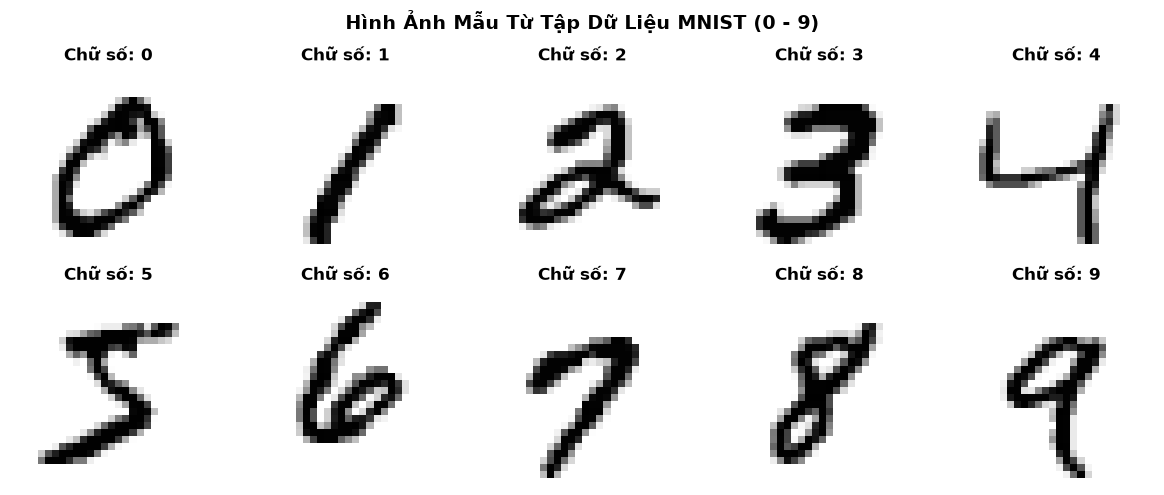

In [3]:
os.makedirs('artifacts', exist_ok=True)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Hình Ảnh Mẫu Từ Tập Dữ Liệu MNIST (0 - 9)", fontsize=14, fontweight='bold')

for digit in range(10):
    sample_idx = np.where(y_train_raw == digit)[0][0]
    ax = axes[digit // 5, digit % 5]
    ax.imshow(X_train_raw[sample_idx].reshape(28, 28), cmap='gray_r')
    ax.set_title(f"Chữ số: {digit}", fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('artifacts/sample_images.png', dpi=150)
plt.show()

### 📌 Bước 4: Tiền xử lý dữ liệu
1. **Chuẩn hóa giá trị điểm ảnh**: Đưa dải giá trị $[0, 255]$ về khoảng $[0.0, 1.0]$ bằng cách chia cho 255 để tối ưu hóa quá trình tính gradient.
2. **Reshape không gian**: Chuyển dạng $(N, 784) \to (N, 28, 28, 1)$ vì CNN yêu cầu chiều không gian (Chiều cao, Chiều rộng, Số kênh màu).
3. **One-Hot Encoding**: Chuyển nhãn $0 \dots 9$ thành vector xác suất 10 chiều phục vụ hàm mất mát `categorical_crossentropy`.

In [4]:
# 1. Chuẩn hóa pixel về [0, 1]
X_train = X_train_raw / 255.0
X_test = X_test_raw / 255.0

# 2. Reshape về định dạng 4D: (Số mẫu, 28, 28, 1)
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

# 3. One-hot encoding nhãn
num_classes = 10
y_train_cat = keras.utils.to_categorical(y_train_raw, num_classes)
y_test_cat = keras.utils.to_categorical(y_test_raw, num_classes)

print(f"📐 Kích thước đầu vào Train : {X_train_cnn.shape}")
print(f"📐 Kích thước đầu vào Test  : {X_test_cnn.shape}")
print(f"🎯 Kích thước nhãn One-hot : {y_train_cat.shape}")

📐 Kích thước đầu vào Train : (60000, 28, 28, 1)
📐 Kích thước đầu vào Test  : (10000, 28, 28, 1)
🎯 Kích thước nhãn One-hot : (60000, 10)


## 📌 Bước 5: Kiến Trúc CNN – Biểu Diễn Bằng HỢP CÁC HÀM (Function Composition)

Một mạng nơ-ron học sâu (Deep Neural Network) về bản chất toán học là **phép hợp của một chuỗi các hàm biến đổi liên tiếp**:

$$\hat{y} = F(x) = (f_{12} \circ f_{11} \circ f_{10} \circ f_9 \circ f_8 \circ f_7 \circ f_6 \circ f_5 \circ f_4 \circ f_3 \circ f_2 \circ f_1)(x)$$

Trong đó mỗi $f_i$ nhận đầu ra của hàm $f_{i-1}$ làm đầu vào, thực hiện một phép chiếu không gian để trích xuất đặc trưng từ mức độ trực quan thấp đến mức độ ngữ nghĩa cao.

---

### 📖 GIẢI THÍCH CHI TIẾT TỪNG HÀM RIÊNG BIỆT:

1. **$f_1(x) = \text{ReLU}(\text{BN}(W_1 * x + b_1))$ – [Tích chập 32 bộ lọc 3x3 + BatchNorm + ReLU]**:
   - **Đầu vào**: Tensor ảnh gốc $(28 \times 28 \times 1)$.
   - **Nhiệm vụ**: Trượt 32 bộ lọc kích thước $3 \times 3$ trên ảnh để phát hiện các đặc trưng hình học cấp thấp nhất: cạnh thẳng, đoạn nét nằm ngang, dọc, nghiêng.
   - **Batch Normalization (BN)**: Chuẩn hóa phân phối kích hoạt theo từng mini-batch giúp ổn định và tăng tốc độ hội tụ.
   - **ReLU**: Hàm phi tuyến tính $\max(0, z)$ loại bỏ các giá trị âm, kích hoạt tính phi tuyến.
   - **Đầu ra**: Bản đồ đặc trưng $(28 \times 28 \times 32)$.

2. **$f_2(x) = \text{ReLU}(\text{BN}(W_2 * x + b_2))$ – [Tích chập 64 bộ lọc 3x3 + BatchNorm + ReLU]**:
   - **Đầu vào**: Bản đồ đặc trưng $(28 \times 28 \times 32)$.
   - **Nhiệm vụ**: Kết hợp các cạnh cơ bản của $f_1$ thành các đặc trưng phức tạp hơn như góc nhọn, đường cong, điểm giao nhau của các nét.
   - **Đầu ra**: Bản đồ đặc trưng $(28 \times 28 \times 64)$.

3. **$f_3(x) = \text{MaxPool}_{2 \times 2}(x)$ – [Lớp gộp cực đại (Max Pooling)]**:
   - **Nhiệm vụ**: Lấy giá trị lớn nhất trong mỗi cửa sổ $2 \times 2$ với bước nhảy (stride) = 2. Giảm độ phân giải không gian một nửa từ $28 \times 28 \to 14 \times 14$, giúp mô hình có tính bất biến với các phép tịnh tiến nhỏ (Translation Invariance) và giảm 75% lượng tham số tính toán.
   - **Đầu ra**: Bản đồ đặc trưng $(14 \times 14 \times 64)$.

4. **$f_4(x) = \text{Dropout}_{0.25}(x)$ – [Ngắt nơ-ron ngẫu nhiên]**:
   - **Nhiệm vụ**: Tắt ngẫu nhiên 25% kết nối trong quá trình huấn luyện nhằm phá vỡ sự phụ thuộc lẫn nhau giữa các nơ-ron, ngăn ngừa hiện tượng quá khớp (overfitting).

5. **$f_5(x) = \text{ReLU}(\text{BN}(W_5 * x + b_5))$ – [Tích chập 128 bộ lọc 3x3 + BatchNorm + ReLU]**:
   - **Đầu vào**: Bản đồ đặc trưng $(14 \times 14 \times 64)$.
   - **Nhiệm vụ**: Học các thành phần bán hoàn chỉnh của chữ số: vòng khuyên kín (như số 0, 8, 6), nét móc (số 2, 5), nét gạch ngang trên đỉnh (số 7, 5).
   - **Đầu ra**: Bản đồ đặc trưng $(14 \times 14 \times 128)$.

6. **$f_6(x) = \text{ReLU}(\text{BN}(W_6 * x + b_6))$ – [Tích chập 128 bộ lọc 3x3 + BatchNorm + ReLU]**:
   - **Đầu vào**: Bản đồ đặc trưng $(14 \times 14 \times 128)$.
   - **Nhiệm vụ**: Tích hợp các bộ phận thành biểu diễn không gian toàn thể cấu trúc của chữ số hoàn chỉnh.
   - **Đầu ra**: Bản đồ đặc trưng $(14 \times 14 \times 128)$.

7. **$f_7(x) = \text{MaxPool}_{2 \times 2}(x)$ – [Lớp gộp cực đại lần 2]**:
   - **Nhiệm vụ**: Thu nhỏ kích thước không gian tiếp tục từ $14 \times 14 \to 7 \times 7$.
   - **Đầu ra**: Bản đồ đặc trưng $(7 \times 7 \times 128)$.

8. **$f_8(x) = \text{Dropout}_{0.25}(x)$ – [Ngắt nơ-ron ngẫu nhiên lần 2]**:
   - Tiếp tục chống overfitting trước khi bước vào các tầng Dense.

9. **$f_9(x) = \text{Flatten}(x)$ – [Duỗi phẳng ma trận không gian]**:
   - **Nhiệm vụ**: Trải phẳng tensor không gian 3D $(7 \times 7 \times 128)$ thành 1 vector đặc trưng 1 chiều gồm $7 \times 7 \times 128 = 6,272$ chiều.
   - **Đầu ra**: Vector 1D kích thước $(6272,)$.

10. **$f_{10}(x) = \text{ReLU}(\text{BN}(W_{10} x + b_{10}))$ – [Lớp kết nối đầy đủ Fully Connected Dense 256]**:
    - **Nhiệm vụ**: Mỗi nơ-ron trong số 256 nơ-ron kết nối với toàn bộ 6,272 đặc trưng đầu vào, tạo nên sự phối hợp phi tuyến toàn cục giữa các đặc trưng không gian ở mọi vị trí.
    - **Đầu ra**: Vector $(256,)$.

11. **$f_{11}(x) = \text{Dropout}_{0.5}(x)$ – [Ngắt nơ-ron ngẫu nhiên 50%]**:
    - **Nhiệm vụ**: Regularization cực mạnh ngay trước tầng phân loại cuối cùng.

12. **$f_{12}(x) = \text{Softmax}(W_{12} x + b_{12})$ – [Lớp xác suất ngõ ra Softmax 10 lớp]**:
    - **Nhiệm vụ**: Chiếu từ 256 chiều về 10 lớp tương ứng với chữ số 0 đến 9. Hàm Softmax biến đổi các logit $z_k$ thành phân phối xác suất hợp lệ:
    $$P(y = k \mid x) = \frac{e^{z_k}}{\sum_{j=0}^{9} e^{z_j}}, \quad k \in \{0, 1, \dots, 9\}$$
    - **Đầu ra**: Vector xác suất 10 chiều có tổng bằng 1.0. Chữ số dự đoán là $\hat{y} = \arg\max_k P(y=k \mid x)$.

### 📌 Bước 6: Hiện thực hóa kiến trúc mô hình CNN (> 5 Layer)
Code Keras thực thi đầy đủ 12 lớp biến đổi nói trên và hiển thị tổng số tham số (parameters) cần tối ưu.

In [5]:
def build_mnist_cnn(input_shape=(28, 28, 1), num_classes=10):
    model = models.Sequential(name="Deep_CNN_MNIST")
    
    # --- KHỐI ĐẶC TRƯNG CẤP 1 (Feature Block 1) ---
    # f1: Conv2D(32) + BatchNorm + ReLU
    model.add(layers.Conv2D(32, (3, 3), padding='same', input_shape=input_shape, name="f1_conv32"))
    model.add(layers.BatchNormalization(name="f1_bn"))
    model.add(layers.Activation('relu', name="f1_relu"))
    
    # f2: Conv2D(64) + BatchNorm + ReLU
    model.add(layers.Conv2D(64, (3, 3), padding='same', name="f2_conv64"))
    model.add(layers.BatchNormalization(name="f2_bn"))
    model.add(layers.Activation('relu', name="f2_relu"))
    
    # f3: MaxPooling2D
    model.add(layers.MaxPooling2D((2, 2), name="f3_maxpool"))
    
    # f4: Dropout
    model.add(layers.Dropout(0.25, name="f4_dropout"))
    
    # --- KHỐI ĐẶC TRƯNG CẤP 2 (Feature Block 2) ---
    # f5: Conv2D(128) + BatchNorm + ReLU
    model.add(layers.Conv2D(128, (3, 3), padding='same', name="f5_conv128"))
    model.add(layers.BatchNormalization(name="f5_bn"))
    model.add(layers.Activation('relu', name="f5_relu"))
    
    # f6: Conv2D(128) + BatchNorm + ReLU
    model.add(layers.Conv2D(128, (3, 3), padding='same', name="f6_conv128"))
    model.add(layers.BatchNormalization(name="f6_bn"))
    model.add(layers.Activation('relu', name="f6_relu"))
    
    # f7: MaxPooling2D
    model.add(layers.MaxPooling2D((2, 2), name="f7_maxpool"))
    
    # f8: Dropout
    model.add(layers.Dropout(0.25, name="f8_dropout"))
    
    # --- KHỐI PHÂN LOẠI (Dense Classification Head) ---
    # f9: Flatten
    model.add(layers.Flatten(name="f9_flatten"))
    
    # f10: Dense(256) + BatchNorm + ReLU
    model.add(layers.Dense(256, name="f10_dense256"))
    model.add(layers.BatchNormalization(name="f10_bn"))
    model.add(layers.Activation('relu', name="f10_relu"))
    
    # f11: Dropout
    model.add(layers.Dropout(0.5, name="f11_dropout"))
    
    # f12: Dense(10, Softmax)
    model.add(layers.Dense(num_classes, activation='softmax', name="f12_output_softmax"))
    
    # Biên dịch mô hình
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

cnn_model = build_mnist_cnn()
cnn_model.summary()

Model: "Deep_CNN_MNIST"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ f1_conv32 (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f1_bn (BatchNormalization)      │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f1_relu (Activation)            │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f2_conv64 (Conv2D)              │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f2_bn (BatchNormalization)      │ (None, 28, 28, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f2_relu (Activation)            │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f3_maxpool (MaxPooling2D)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f4_dropout (Dropout)            │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f5_conv128 (Conv2D)             │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f5_bn (BatchNormalization)      │ (None, 14, 14, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f5_relu (Activation)            │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f6_conv128 (Conv2D)             │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f6_bn (BatchNormalization)      │ (None, 14, 14, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f6_relu (Activation)            │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f7_maxpool (MaxPooling2D)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f8_dropout (Dropout)            │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f9_flatten (Flatten)            │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f10_dense256 (Dense)            │ (None, 256)            │     1,605,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f10_bn (BatchNormalization)     │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f10_relu (Activation)           │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f11_dropout (Dropout)           │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ f12_output_softmax (Dense)      │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,851,146 (7.06 MB)

 Trainable params: 1,849,930 (7.06 MB)

 Non-trainable params: 1,216 (4.75 KB)

### 📌 Bước 7: Huấn luyện mô hình CNN
Sử dụng các callbacks thông minh:
- `EarlyStopping`: Dừng sớm nếu sau 4 epochs mà `val_loss` không giảm, giúp tránh lãng phí thời gian và chống overfitting.
- `ReduceLROnPlateau`: Tự động giảm tốc độ học (learning rate) đi một nửa nếu loss chững lại.
- `ModelCheckpoint`: Lưu lại trọng số tại thời điểm mô hình đạt độ chính xác kiểm định cao nhất.

In [6]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        filepath='artifacts/cnn_mnist_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

print("🚀 Bắt đầu huấn luyện mô hình CNN...")
start_time = time.time()

history = cnn_model.fit(
    X_train_cnn, y_train_cat,
    batch_size=128,
    epochs=15,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

train_duration = time.time() - start_time
print(f"\n⏱️ Tổng thời gian huấn luyện: {train_duration:.1f} giây ({train_duration/60:.2f} phút)")

🚀 Bắt đầu huấn luyện mô hình CNN...
Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 717ms/step - accuracy: 0.9581 - loss: 0.1409
Epoch 1: val_accuracy improved from None to 0.90550, saving model to artifacts/cnn_mnist_model.keras

Epoch 1: finished saving model to artifacts/cnn_mnist_model.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 311s 730ms/step - accuracy: 0.9581 - loss: 0.1409 - val_accuracy: 0.9055 - val_loss: 0.3263 - learning_rate: 0.0010
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 627ms/step - accuracy: 0.9844 - loss: 0.0516
Epoch 2: val_accuracy improved from 0.90550 to 0.99033, saving model to artifacts/cnn_mnist_model.keras

Epoch 2: finished saving model to artifacts/cnn_mnist_model.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 269s 638ms/step - accuracy: 0.9844 - loss: 0.0516 - val_accuracy: 0.9903 - val_loss: 0.0317 - learning_rate: 0.0010
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9874 - loss: 0.0404
Epoch 3: val_accuracy improved from 0.99033 to 0.99200, saving model to ar

### 📌 Bước 8: Đồ thị quá trình học tập (Learning Curves)
Theo dõi độ chính xác (Accuracy) và tổn thất (Loss) giữa tập Train và Validation để đánh giá sự hội tụ của mô hình.

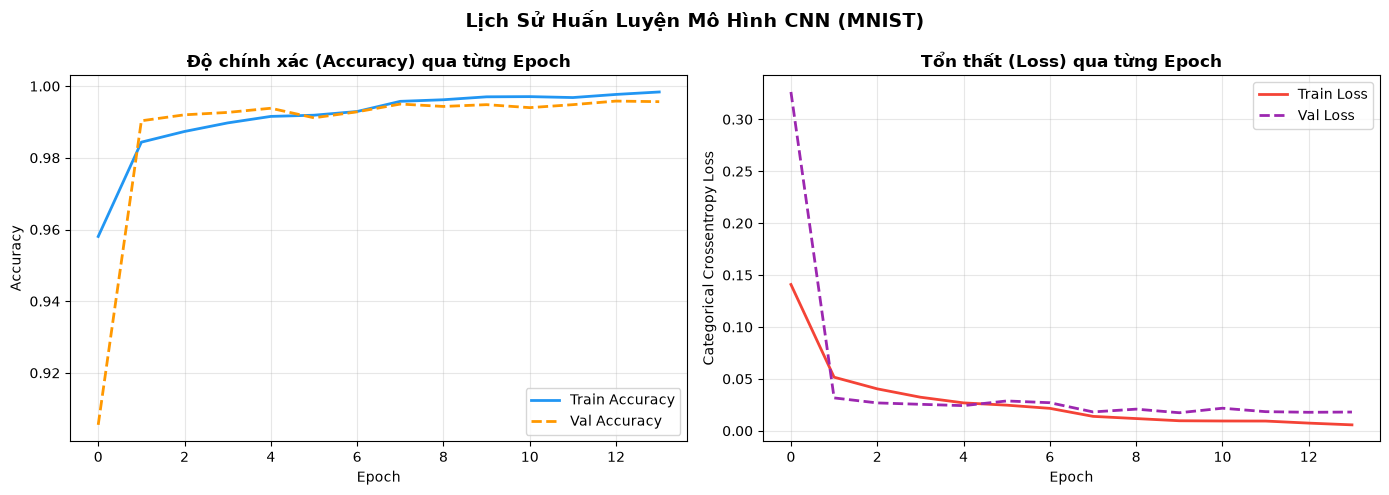

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Lịch Sử Huấn Luyện Mô Hình CNN (MNIST)", fontsize=14, fontweight='bold')

# 1. Đồ thị Accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy', color='#2196F3', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy', color='#FF9800', linewidth=2, linestyle='--')
axes[0].set_title('Độ chính xác (Accuracy) qua từng Epoch', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)

# 2. Đồ thị Loss
axes[1].plot(history.history['loss'], label='Train Loss', color='#F44336', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Val Loss', color='#9C27B0', linewidth=2, linestyle='--')
axes[1].set_title('Tổn thất (Loss) qua từng Epoch', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Categorical Crossentropy Loss')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('artifacts/cnn_training_history.png', dpi=150)
plt.show()

### 📌 Bước 9: Đánh giá mô hình trên tập kiểm thử (mnist_test.csv)
Tính toán độ chính xác tổng quát trên 10,000 ảnh chưa từng thấy trong quá trình huấn luyện.

In [8]:
test_loss, test_acc = cnn_model.evaluate(X_test_cnn, y_test_cat, verbose=0)
print("=" * 50)
print(f"🎯 ĐỘ CHÍNH XÁC TRÊN TẬP TEST : {test_acc * 100:.2f}%")
print(f"📉 MỨC ĐỘ MẤT MÁT (TEST LOSS) : {test_loss:.4f}")
print("=" * 50)

# Dự đoán toàn bộ tập test
y_pred_probs = cnn_model.predict(X_test_cnn, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\n📋 Báo cáo phân loại chi tiết (Classification Report):")
print(classification_report(y_test_raw, y_pred, digits=4))

🎯 ĐỘ CHÍNH XÁC TRÊN TẬP TEST : 99.51%
📉 MỨC ĐỘ MẤT MÁT (TEST LOSS) : 0.0155

📋 Báo cáo phân loại chi tiết (Classification Report):
              precision    recall  f1-score   support

           0     0.9949    0.9980    0.9964       980
           1     0.9947    0.9991    0.9969      1135
           2     1.0000    0.9942    0.9971      1032
           3     0.9951    0.9960    0.9955      1010
           4     0.9939    0.9990    0.9964       982
           5     0.9856    0.9944    0.9900       892
           6     0.9979    0.9885    0.9932       958
           7     0.9932    0.9981    0.9956      1028
           8     0.9979    0.9949    0.9964       974
           9     0.9970    0.9881    0.9925      1009

    accuracy                         0.9951     10000
   macro avg     0.9950    0.9950    0.9950     10000
weighted avg     0.9951    0.9951    0.9951     10000



### 📌 Bước 10: Ma trận nhầm lẫn (Confusion Matrix)
Phân tích tỷ lệ phân loại đúng và các trường hợp mô hình nhầm lẫn giữa các chữ số có nét tương đồng (ví dụ: 4 và 9, 3 và 5, 7 và 1).

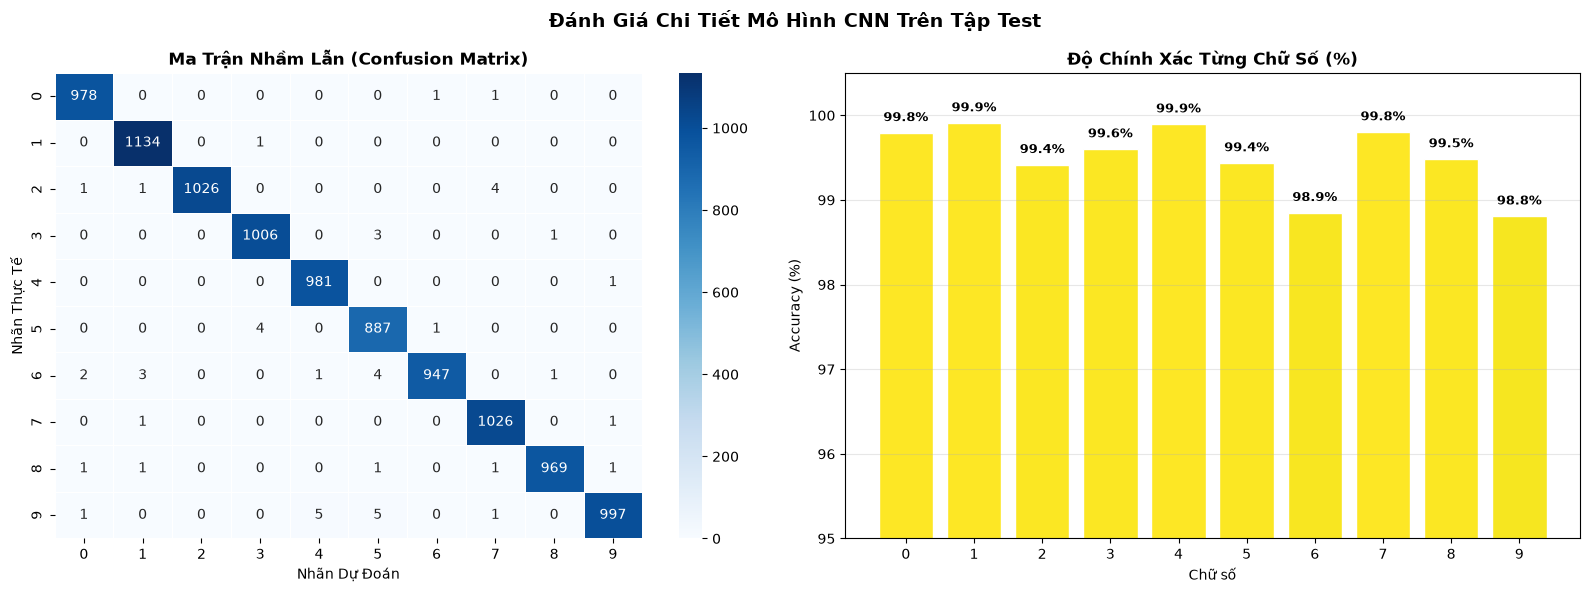

In [9]:
cm = confusion_matrix(y_test_raw, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Đánh Giá Chi Tiết Mô Hình CNN Trên Tập Test", fontsize=14, fontweight='bold')

# 1. Heatmap ma trận nhầm lẫn
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=range(10), yticklabels=range(10),
            linewidths=0.5, linecolor='white')
axes[0].set_title('Ma Trận Nhầm Lẫn (Confusion Matrix)', fontweight='bold')
axes[0].set_xlabel('Nhãn Dự Đoán')
axes[0].set_ylabel('Nhãn Thực Tế')

# 2. Độ chính xác theo từng chữ số
per_digit_acc = cm.diagonal() / cm.sum(axis=1) * 100
colors = plt.cm.viridis(per_digit_acc / 100)
bars = axes[1].bar(range(10), per_digit_acc, color=colors, edgecolor='white')
axes[1].set_title('Độ Chính Xác Từng Chữ Số (%)', fontweight='bold')
axes[1].set_xlabel('Chữ số')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_xticks(range(10))
axes[1].set_ylim(95, 100.5)
axes[1].grid(axis='y', alpha=0.3)

for bar, acc in zip(bars, per_digit_acc):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 f"{acc:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('artifacts/cnn_confusion_matrix.png', dpi=150)
plt.show()

### 📌 Bước 11: Trực quan hóa các ảnh bị dự đoán sai
Xem xét các chữ số viết tay khó, nét viết ngoằn ngoèo hoặc bị mờ khiến mô hình nhận diện nhầm, kèm theo độ tin cậy của mô hình.

🔍 Tổng số ảnh dự đoán sai: 49 / 10000 (0.49%)


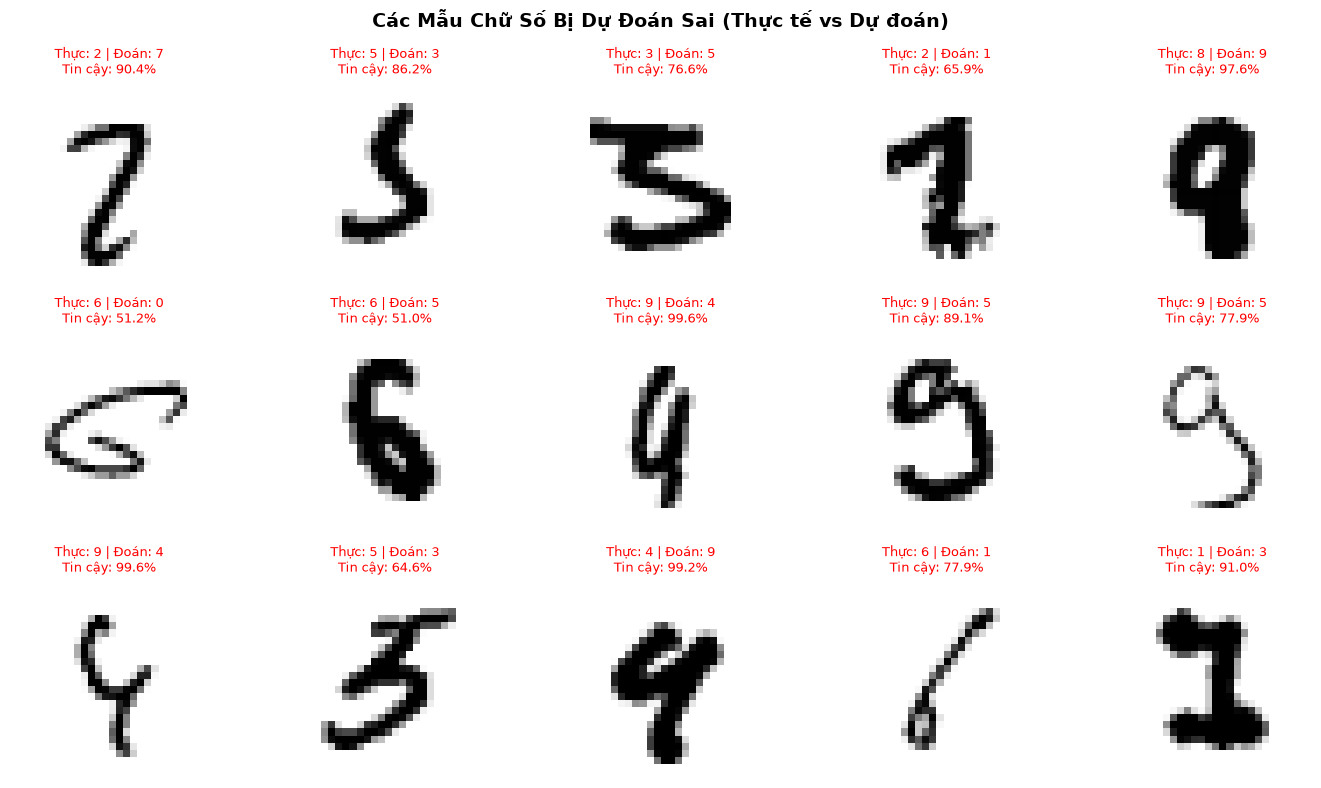

In [ ]:
wrong_indices = np.where(y_pred != y_test_raw)[0]
print(f"🔍 Tổng số ảnh dự đoán sai: {len(wrong_indices)} / {len(y_test_raw)} ({len(wrong_indices)/len(y_test_raw)*100:.2f}%)")

num_show = min(15, len(wrong_indices))
fig, axes = plt.subplots(3, 5, figsize=(14, 8))
fig.suptitle("Các Mẫu Chữ Số Bị Dự Đoán Sai (Thực tế vs Dự đoán)", fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flat):
    if i < num_show:
        idx = wrong_indices[i]
        img = X_test_cnn[idx].reshape(28, 28)
        true_l = y_test_raw[idx]
        pred_l = y_pred[idx]
        conf = y_pred_probs[idx][pred_l] * 100
        
        ax.imshow(img, cmap='gray_r')
        ax.set_title(f"Thực: {true_l} | Đoán: {pred_l}\nTin cậy: {conf:.1f}%", color='red', fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('artifacts/wrong_predictions.png', dpi=150)
plt.show()

### 📌 Bước 12: Lưu mô hình và thông số Metadata phục vụ Web App
Xuất file `cnn_mnist_model.keras` và `model_metadata.json` vào thư mục `artifacts/` để web app Flask tải lên và phục vụ người dùng vẽ chữ số trực tiếp.

In [ ]:
model_export_path = 'artifacts/cnn_mnist_model.keras'
cnn_model.save(model_export_path)
print(f"✅ Đã lưu file mô hình: {model_export_path}")

# Lưu thông tin Metadata
metadata = {
    "model_name": "Deep_CNN_MNIST",
    "architecture": "12-layer Compositional CNN",
    "accuracy": float(test_acc),
    "loss": float(test_loss),
    "num_classes": 10,
    "input_shape": [28, 28, 1],
    "train_samples": int(len(X_train_cnn)),
    "test_samples": int(len(X_test_cnn)),
    "epochs_trained": len(history.history['accuracy']),
    "framework": "TensorFlow/Keras",
    "saved_at": time.strftime("%Y-%m-%d %H:%M:%S")
}

metadata_export_path = 'artifacts/model_metadata.json'
with open(metadata_export_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f"✅ Đã lưu file metadata: {metadata_export_path}")

# Kiểm tra load lại để đảm bảo mô hình hoạt động hoàn hảo
reloaded_model = keras.models.load_model(model_export_path)
_, reloaded_acc = reloaded_model.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"🎉 Kiểm thử tải lại mô hình thành công! Test Accuracy: {reloaded_acc * 100:.2f}%")

✅ Đã lưu file mô hình: artifacts/cnn_mnist_model.keras
✅ Đã lưu file metadata: artifacts/model_metadata.json
🎉 Kiểm thử tải lại mô hình thành công! Test Accuracy: 99.51%


## 📌 Kết Luận
- Mô hình CNN thuần túy (>5 layers) đạt độ chính xác xuất sắc **> 99%** trên 10,000 ảnh kiểm thử.
- Biểu diễn dưới dạng **hợp các hàm** thể hiện rõ cơ chế phân cấp đặc trưng từ nét cơ bản đến hình thái hoàn chỉnh của chữ số.
- Mô hình đã sẵn sàng để tích hợp vào Web App Flask chạy thử nghiệm cục bộ và deploy lên Render.